# LAB-04(SPII)

In [1]:
# Import necessary libraries
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import igraph as ig
from scipy.optimize import root_scalar

In [2]:
# Define probabilities for the first generation
P0 = 1/2
P1 = 1/4
P2 = 1/4

## 04(a)

In [3]:
# Create a directed graph
G = nx.DiGraph()

In [4]:
# Define edges for the tree diagram
edges = [
    ("G0", "G1_P0"), ("G0", "G1_P1"), ("G0", "G1_P2"),
    ("G1_P0", "G2_P0_0"), ("G1_P0", "G2_P0_1"), ("G1_P0", "G2_P0_2"),
    ("G1_P1", "G2_P1_0"), ("G1_P1", "G2_P1_1"), ("G1_P1", "G2_P1_2"),
    ("G1_P2", "G2_P2_0"), ("G1_P2", "G2_P2_1"), ("G1_P2", "G2_P2_2")
]

In [5]:
# Add edges to the graph
G.add_edges_from(edges)

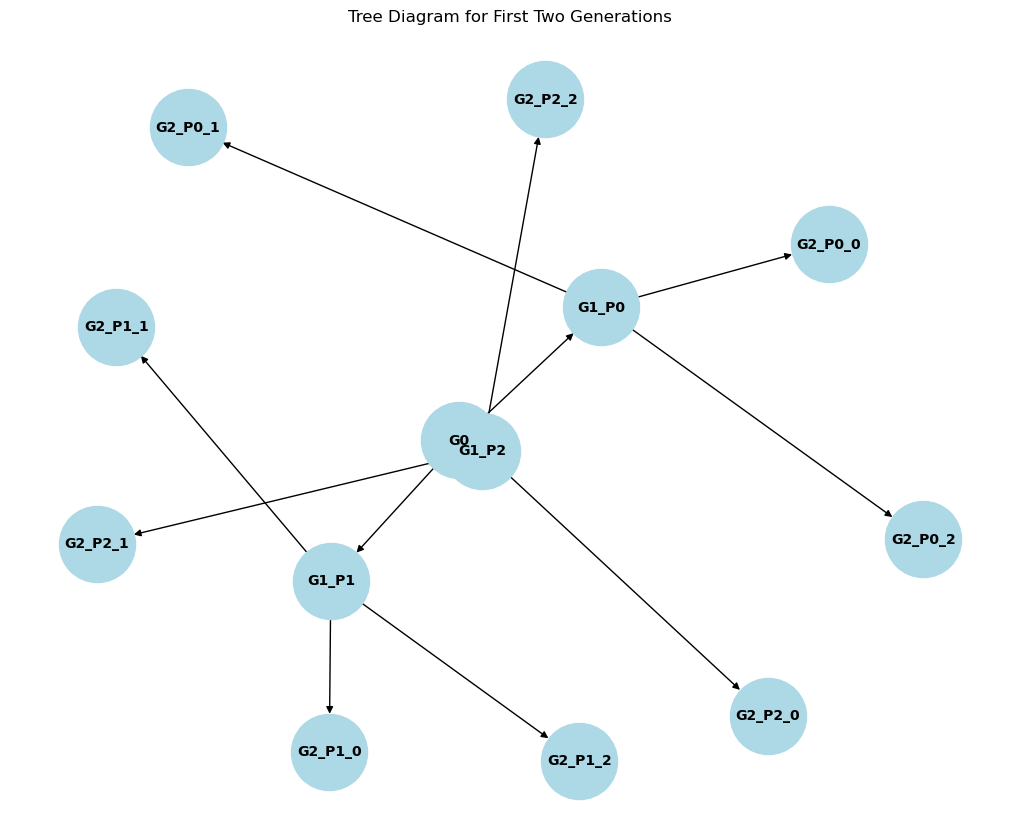

In [6]:
# Draw the tree diagram
plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)  # Use spring layout for better positioning
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', font_size=10, font_weight='bold', arrows=True)
plt.title("Tree Diagram for First Two Generations")
plt.show()

### OR

In [7]:
# Create a directed graph
G = nx.DiGraph()

In [8]:
# Add nodes
G.add_nodes_from(["G0", "G1_P0", "G1_P1", "G1_P2", 
                 "G2_P0_0", "G2_P0_1", "G2_P0_2", 
                 "G2_P1_0", "G2_P1_1", "G2_P1_2", 
                 "G2_P2_0", "G2_P2_1", "G2_P2_2"])

In [9]:
# Add edges with weights (probabilities)
edges = [
    ("G0", "G1_P0"), ("G0", "G1_P1"), ("G0", "G1_P2"),
    ("G1_P0", "G2_P0_0"), ("G1_P0", "G2_P0_1"), ("G1_P0", "G2_P0_2"),
    ("G1_P1", "G2_P1_0"), ("G1_P1", "G2_P1_1"), ("G1_P1", "G2_P1_2"),
    ("G1_P2", "G2_P2_0"), ("G1_P2", "G2_P2_1"), ("G1_P2", "G2_P2_2")
]
G.add_edges_from(edges)

In [10]:
# Define the position for each node manually to avoid 'no position' errors
pos = {
    "G0": [0, 1],
    "G1_P0": [-1, 0], "G1_P1": [0, 0], "G1_P2": [1, 0],
    "G2_P0_0": [-1.5, -1], "G2_P0_1": [-1, -1], "G2_P0_2": [-0.5, -1],
    "G2_P1_0": [-0.5, -1], "G2_P1_1": [0, -1], "G2_P1_2": [0.5, -1],
    "G2_P2_0": [0.5, -1], "G2_P2_1": [1, -1], "G2_P2_2": [1.5, -1]
}

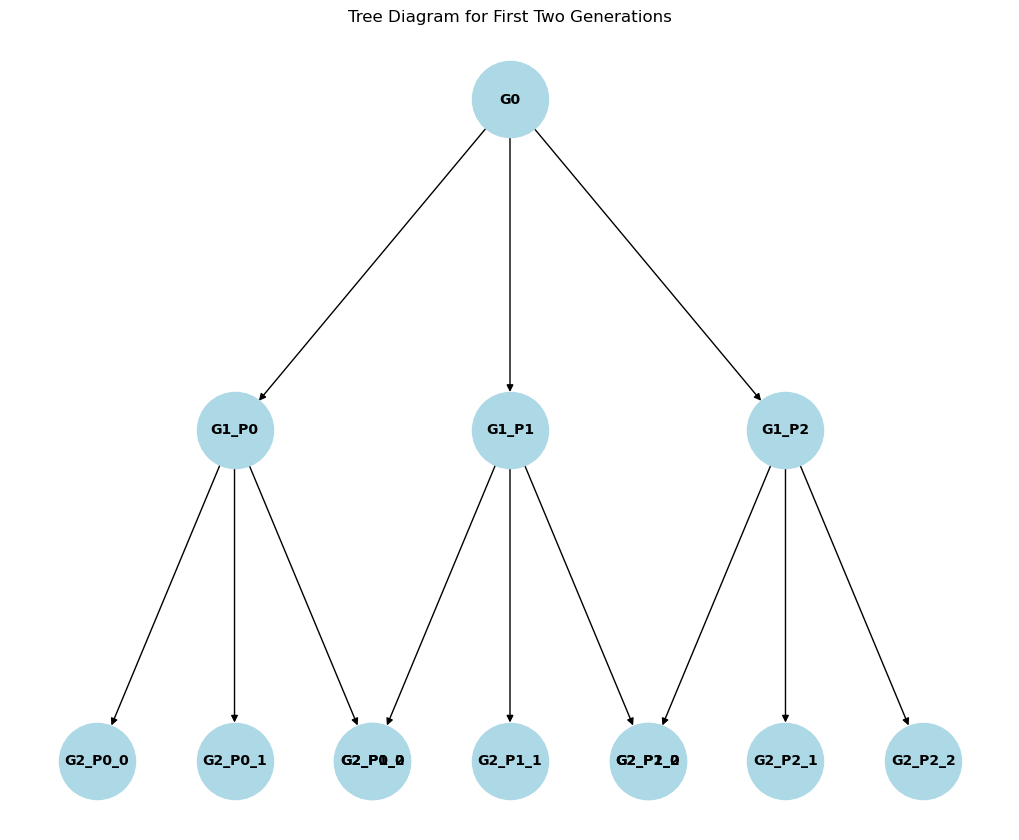

In [11]:
# Draw the graph with the positions
plt.figure(figsize=(10, 8))
nx.draw(G, pos, with_labels=True, node_size=3000, node_color='lightblue', 
        font_size=10, font_weight='bold', arrows=True)
plt.title("Tree Diagram for First Two Generations")
plt.show()

## Mean & Variance of the 2nd Generation

In [12]:
# Mean & Variance for 2nd Generation
mean = (0 * P0 + 1 * P1 + 2 * P2) ** 2
variance = (0 - mean) ** 2 * P0 + (1 - mean) ** 2 * P1 + (2 - mean) ** 2 * P2 + ((0 * P0 + 1 * P1 + 2 * P2) ** 2)

In [13]:
# Output
print(f"Mean of 2nd Generation: {mean}")
print(f"Variance of 2nd Generation: {variance}")

Mean of 2nd Generation: 0.5625
Variance of 2nd Generation: 1.28515625


## 04(b)

In [14]:
# Extinction probability function
def extinction_prob(q):
    return P0 + P1 * q + P2 * q**2 - q

In [15]:
# Solving extinction probability equation
sol = root_scalar(extinction_prob, bracket=[0, 1])

In [16]:
# Output the extinction probability
print(f"Extinction probability: {sol.root}")

Extinction probability: 1.0
